# Homework 4 - The Regression Challenge

Author: Vadim Egorov


**Objective**
- **Build four regression models and compare their performance on the selected dataset.**
- List of models: Linear Regression, Polynomial Regression, Ridge Regression, Lasso Regression
- Which model makes the most accurate predictions on unseen data?

**Dataset**
For this assignemnt I've selected Superconductivty Data provided by the **UCI Machine Learning** Repository.

Link: https://archive.ics.uci.edu/dataset/464/superconductivty%2Bdata

Question: Can the chemical properties of a material predict the temperature at which it becomes superconductive?

## 1. Imports + Setup

In [ ]:
# ucimlrepo isn't preinstalled in Google Colab
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [115]:
from math import comb

import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Larger default size for all plots
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 12

## 2. Load Data

In [116]:
# Fetch dataset 
superconductivty_data = fetch_ucirepo(id=464) 

# Data as pandas dataframes 
X = superconductivty_data.data.features
y = superconductivty_data.data.targets

## 3. EDA — Exploratory Data Analysis

Combine features and target into one DataFrame so it's easier to explore.

In [117]:
df = pd.concat([X, y], axis=1)

display(df.head())
display(df.shape)
display(df.info())

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


(21263, 82)

<class 'pandas.DataFrame'>
RangeIndex: 21263 entries, 0 to 21262
Data columns (total 82 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   number_of_elements               21263 non-null  int64  
 1   mean_atomic_mass                 21263 non-null  float64
 2   wtd_mean_atomic_mass             21263 non-null  float64
 3   gmean_atomic_mass                21263 non-null  float64
 4   wtd_gmean_atomic_mass            21263 non-null  float64
 5   entropy_atomic_mass              21263 non-null  float64
 6   wtd_entropy_atomic_mass          21263 non-null  float64
 7   range_atomic_mass                21263 non-null  float64
 8   wtd_range_atomic_mass            21263 non-null  float64
 9   std_atomic_mass                  21263 non-null  float64
 10  wtd_std_atomic_mass              21263 non-null  float64
 11  mean_fie                         21263 non-null  float64
 12  wtd_mean_fie                 

None

### 3.1 Summary statistics

In [118]:
df.describe()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
count,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,...,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000
mean,4.115224,87.557631,72.988310,71.290627,58.539916,1.165608,1.063884,115.601251,33.225218,44.391893,...,3.153127,3.056536,3.055885,1.295682,1.052841,2.041010,1.483007,0.839342,0.673987,34.421219
std,1.439295,29.676497,33.490406,31.030272,36.651067,0.364930,0.401423,54.626887,26.967752,20.035430,...,1.191249,1.046257,1.174815,0.393155,0.380291,1.242345,0.978176,0.484676,0.455580,34.254362
min,1.000000,6.941000,6.423452,5.320573,1.960849,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000210
25%,3.000000,72.458076,52.143839,58.041225,35.248990,0.966676,0.775363,78.512902,16.824174,32.890369,...,2.116732,2.279705,2.091251,1.060857,0.775678,1.000000,0.921454,0.451754,0.306892,5.365000
50%,4.000000,84.922750,60.696571,66.361592,39.918385,1.199541,1.146783,122.906070,26.636008,45.123500,...,2.618182,2.615321,2.434057,1.368922,1.166532,2.000000,1.063077,0.800000,0.500000,20.000000
75%,5.000000,100.404410,86.103540,78.116681,73.113234,1.444537,1.359418,154.119320,38.356908,59.322812,...,4.026201,3.727919,3.914868,1.589027,1.330801,3.000000,1.918400,1.200000,1.020436,63.000000
max,9.000000,208.980400,208.980400,208.980400,208.980400,1.983797,1.958203,207.972460,205.589910,101.019700,...,7.000000,7.000000,7.000000,2.141963,1.949739,6.000000,6.992200,3.000000,3.000000,185.000000


### 3.2 Missing values and duplicates

In [119]:
missing_values_num = df.isnull().sum().sum()
duplicate_rows_num = df.duplicated().sum()

print(f"Number of missing values: {missing_values_num}")
print(f"Number of duplicate rows: {duplicate_rows_num}")

Number of missing values: 0
Number of duplicate rows: 66


**Missing values:** none. Every one of the 82 columns is fully populated, so no imputation or row dropping is needed for missing data.

**Duplicates:** 66 rows are exact copies (same features *and* same target). They're removed in Preprocessing so the same material can't land in both the training and test sets.

### 3.3 Target variable: `critical_temp`

In [120]:
df['critical_temp'].describe()

count    21263.000000
mean        34.421219
std         34.254362
min          0.000210
25%          5.365000
50%         20.000000
75%         63.000000
max        185.000000
Name: critical_temp, dtype: float64

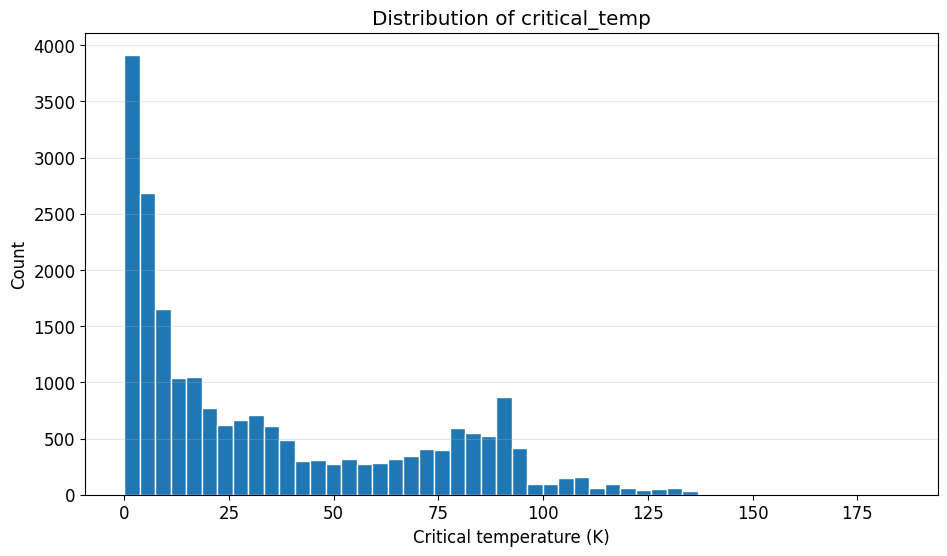

In [121]:
plt.hist(df['critical_temp'], bins=50, edgecolor='white')
plt.xlabel("Critical temperature (K)")
plt.ylabel("Count")
plt.title("Distribution of critical_temp")
plt.grid(axis='y', alpha=0.3)
plt.show()

- `critical_temp` ranges from ~0 K to 185 K, with a mean of 34.4 K and a median of 20 K.
- The distribution is strongly **right-skewed**. Most materials become superconducting below ~10 K, and there's a second cluster around 75–100 K.
- Because of this shape, a linear model will probably have trouble with the high-temperature group.

### 3.4 Correlation with the target

In [122]:
corr_target = df.corr()['critical_temp'].drop('critical_temp')
top_corr = corr_target.abs().sort_values(ascending=False).head(10)
corr_target[top_corr.index]

wtd_std_ThermalConductivity    0.721271
range_ThermalConductivity      0.687654
range_atomic_radius            0.653759
std_ThermalConductivity        0.653632
wtd_mean_Valence              -0.632401
wtd_entropy_atomic_mass        0.626930
wtd_gmean_Valence             -0.615653
wtd_entropy_atomic_radius      0.603494
number_of_elements             0.601069
range_fie                      0.600790
Name: critical_temp, dtype: float64

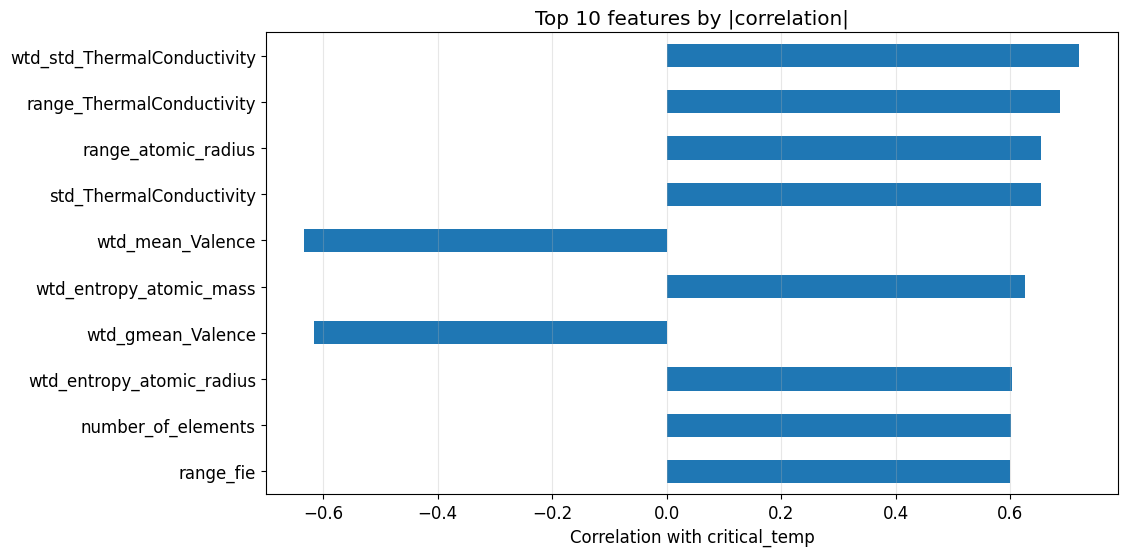

In [123]:
corr_target[top_corr.index].plot(kind='barh')
plt.xlabel("Correlation with critical_temp")
plt.title("Top 10 features by |correlation|")
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.show()

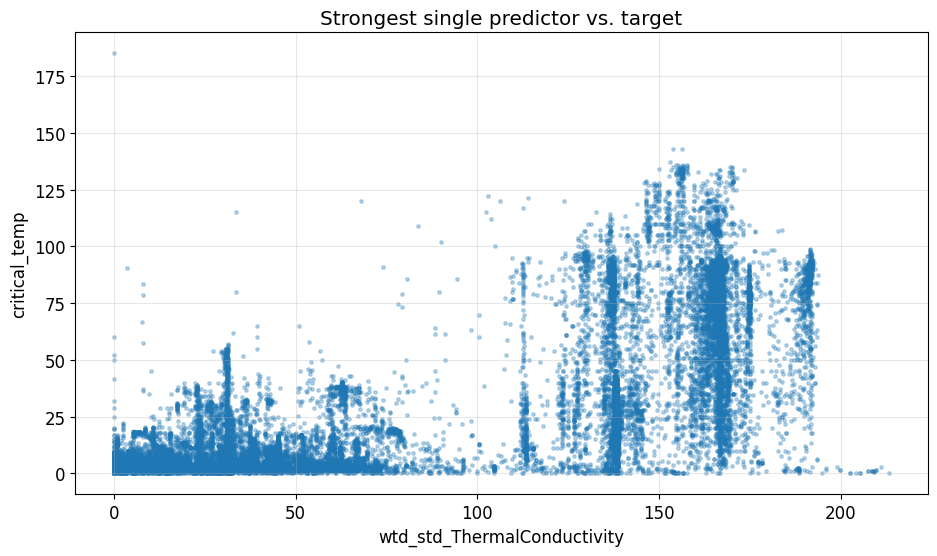

In [124]:
plt.scatter(df['wtd_std_ThermalConductivity'], df['critical_temp'], s=6, alpha=0.3)
plt.xlabel("wtd_std_ThermalConductivity")
plt.ylabel("critical_temp")
plt.title("Strongest single predictor vs. target")
plt.grid(alpha=0.3)
plt.show()

- The thermal conductivity features are the strongest predictors (`wtd_std_ThermalConductivity` r = 0.72, `range_ThermalConductivity` r = 0.69). Atomic radius range (r = 0.65) and Valence (r ≈ −0.63) come next.
- The Valence features are **negatively** correlated: materials with a lower average valence tend to have a higher critical temperature.
- The scatter plot shows that the relationship isn't cleanly linear. Below ~100 the critical temperature stays mostly low, and above ~100 it spreads widely. This suggests polynomial terms may help.

### 3.5 Correlation between features

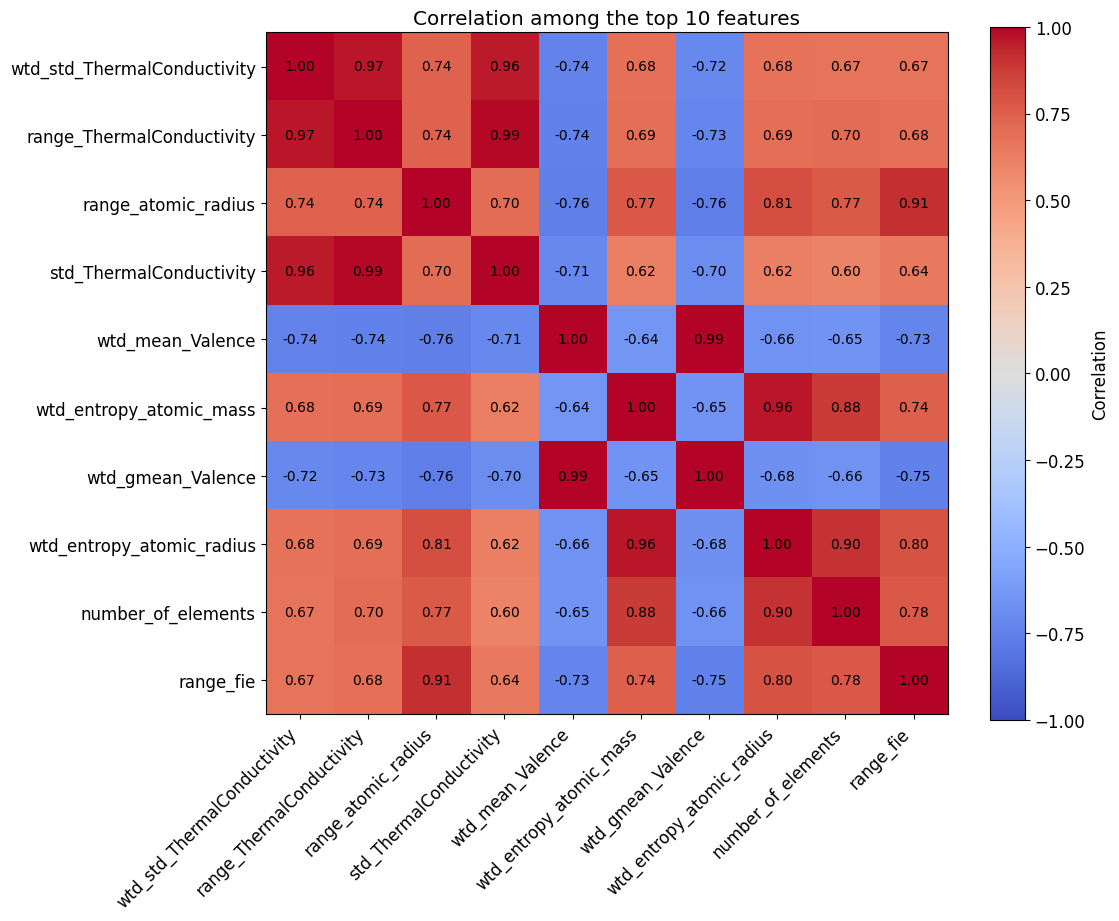

In [125]:
top_features = top_corr.index
feature_corr = df[top_features].corr()

plt.figure(figsize=(11, 9))
plt.imshow(feature_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(top_features)), top_features, rotation=45, ha='right')
plt.yticks(range(len(top_features)), top_features)

# Write the correlation value inside each square
for i in range(len(top_features)):
    for j in range(len(top_features)):
        plt.text(j, i, f"{feature_corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=10)

plt.title("Correlation among the top 10 features")
plt.show()

Many features are strongly correlated with each other. For example, `wtd_std`, `range` and `std` of ThermalConductivity are nearly identical (r > 0.9), and so are `wtd_mean_Valence` and `wtd_gmean_Valence`. This happens because each element property is summarized with 10 related statistics (mean, weighted mean, geometric mean, entropy, range, std, …).

This **multicollinearity** doesn't hurt prediction much, but it makes individual linear regression coefficients unstable and hard to interpret. Ridge and Lasso regularization are designed to handle exactly this.

## 4. Preprocessing
- Convert categorical variables into numerical features if necessary. (No need to do this, because there are no categorical variables)
- Identify the input features (X) and target variable (y).
- Split the dataset into training and testing sets using `random_state=42`.

### 4.1 Remove duplicates

In [126]:
df = df.drop_duplicates()
df.shape

(21197, 82)

### 4.2 Get X and y

In [127]:
X, y = df.drop(columns=['critical_temp']), df['critical_temp']
X.shape, y.shape

((21197, 81), (21197,))

### 4.3 Train/test split

In [128]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (16957, 81)
Test:  (4240, 81)


### 4.4 Feature selection
All four models use the same 3 input features, so they can be compared directly.

**Why not use all 81 features?** The polynomial models make this impractical. For `n` input features and degree `d`, `PolynomialFeatures` creates C(n + d, d) − 1 columns:

In [129]:
train_corr = X_train.corrwith(y_train)
train_corr.sort_values(key=abs, ascending=False).head(10)

wtd_std_ThermalConductivity    0.719833
range_ThermalConductivity      0.686312
range_atomic_radius            0.652264
std_ThermalConductivity        0.651618
wtd_mean_Valence              -0.630782
wtd_entropy_atomic_mass        0.627572
wtd_gmean_Valence             -0.614266
wtd_entropy_atomic_radius      0.604762
number_of_elements             0.601846
range_fie                      0.601020
dtype: float64

Simply taking the top 3 would give `wtd_std_ThermalConductivity`, `range_ThermalConductivity` and `std_ThermalConductivity`: three versions of nearly the same information (r > 0.95 with each other, see 3.5). **So I will take take the best feature from each of the three most predictive element properties.**

In [130]:
selected_features = [
    'wtd_std_ThermalConductivity',
    'range_atomic_radius',
    'wtd_mean_Valence',
]

train_corr[selected_features]

wtd_std_ThermalConductivity    0.719833
range_atomic_radius            0.652264
wtd_mean_Valence              -0.630782
dtype: float64

In [131]:
X_train[selected_features].corr()

,wtd_std_ThermalConductivity,range_atomic_radius,wtd_mean_Valence
wtd_std_ThermalConductivity,1.000000,0.735581,-0.733528
range_atomic_radius,0.735581,1.000000,-0.755151
wtd_mean_Valence,-0.733528,-0.755151,1.000000


In [132]:
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

X_train_sel.shape, X_test_sel.shape

((16957, 3), (4240, 3))

**Why these features:**
- `wtd_std_ThermalConductivity` (r = +0.72): how different the elements' thermal conductivities are, weighted by their amounts in the formula. The strongest single predictor in the dataset.
- `range_atomic_radius` (r = +0.65): the size difference between the largest and smallest atom in the material.
- `wtd_mean_Valence` (r = −0.63): the average number of bonding electrons per atom.

They're the three strongest predictors that each describe a *different* physical property (thermal, structural, electronic).

## 5. Model 1: Linear Regression
- Train a multiple linear regression model using the selected features.
- Report its coefficients and intercept. What do the coefficients tell you?

### 5.1 Train the model
This model uses the 3 features selected in section 4.4.

In [133]:
linear_model = LinearRegression()
linear_model.fit(X_train_sel, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


### 5.2 Evaluate

In [134]:
y_train_pred = linear_model.predict(X_train_sel)
y_test_pred = linear_model.predict(X_test_sel)

In [135]:
lr_train_r2 = r2_score(y_train, y_train_pred)
lr_test_r2 = r2_score(y_test, y_test_pred)
lr_mae = mean_absolute_error(y_test, y_test_pred)
lr_mse = mean_squared_error(y_test, y_test_pred)

print("Training R2:", lr_train_r2)
print("Testing R2: ", lr_test_r2)
print("Test MAE:   ", lr_mae)
print("Test MSE:   ", lr_mse)

Training R2: 0.5566404640489775
Testing R2:  0.5649534035037045
Test MAE:    17.560785669801653
Test MSE:    512.1136250858639


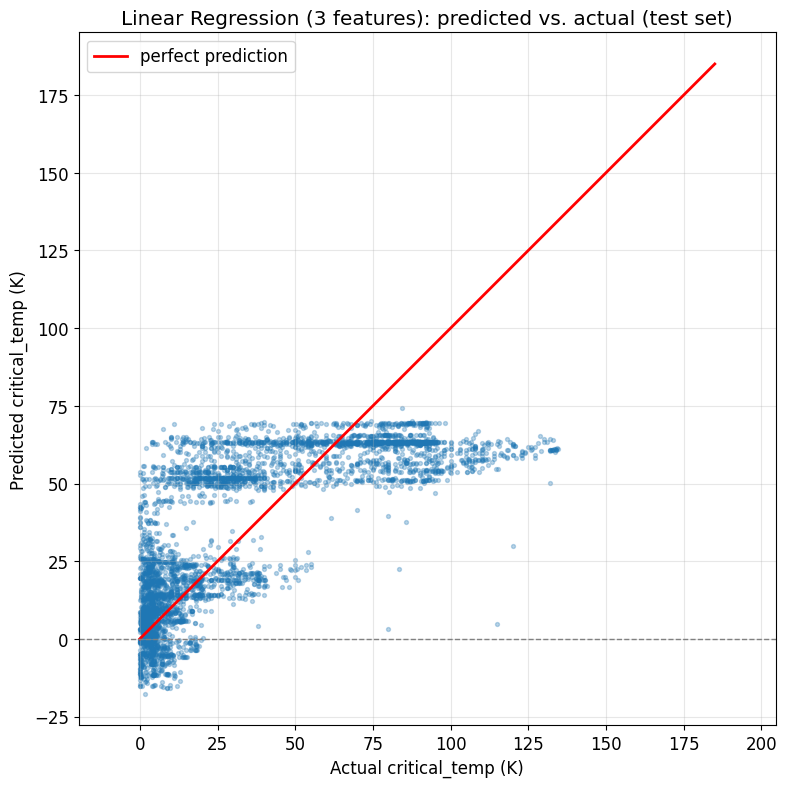

In [136]:
plt.figure(figsize=(9, 9))
plt.scatter(y_test, y_test_pred, s=8, alpha=0.3)
plt.plot([0, 185], [0, 185], color='red', linewidth=2, label='perfect prediction')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.xlabel("Actual critical_temp (K)")
plt.ylabel("Predicted critical_temp (K)")
plt.title("Linear Regression (3 features): predicted vs. actual (test set)")
plt.axis('equal')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- **Training R2 = 0.557, Testing R2 = 0.565.** With 3 features, the model explains about 56% of the variance in critical temperature. Train and test scores are almost identical, so there's **no overfitting**. The model is too simple for the data (**underfitting**).
- **MAE = 17.6 K:** on average, predictions are off by about 18 K. That's large when the median critical temperature is only 20 K.
- The predicted-vs-actual plot shows where it fails:
  - **Predictions top out at about 70 K.** The model never predicts higher than that, so every material above ~70 K is underestimated, some by more than 50 K.
  - **It splits materials into two bands** (roughly 0–25 K and 50–70 K) rather than following the diagonal. Within the upper band, the prediction is about the same whether the actual value is 5 K or 130 K.
  - It predicts **negative temperatures** for some materials, which is physically impossible. A linear regression model has no way of knowing that 0 K is a lower limit.

### 5.3 Coefficients and intercept

In [137]:
linear_model.intercept_

6.291832116344697

In [138]:
coefficients = pd.Series(linear_model.coef_, index=selected_features)
coefficients

wtd_std_ThermalConductivity    0.255800
range_atomic_radius            0.106550
wtd_mean_Valence              -3.588489
dtype: float64

The features are on different scales, so the raw coefficients can't be compared directly. Multiplying each coefficient by its feature's standard deviation gives the change in predicted temperature for a *typical* change in that feature:

In [139]:
X_train_sel.describe().loc[['mean', 'std', 'min', 'max']]

,wtd_std_ThermalConductivity,range_atomic_radius,wtd_mean_Valence
mean,96.368060,139.431739,3.154349
std,63.572496,67.148336,1.193932
min,0.000000,0.000000,1.000000
max,213.300452,256.000000,7.000000


In [140]:
coefficients * X_train_sel.std()

wtd_std_ThermalConductivity    16.261828
range_atomic_radius             7.154632
wtd_mean_Valence               -4.284411
dtype: float64

**What the coefficients tell us:**
- `wtd_std_ThermalConductivity` = **+0.256**: each extra unit of spread in thermal conductivity adds about 0.26 K to the prediction.
- `range_atomic_radius` = **+0.107**: each extra unit of difference between the largest and smallest atom adds about 0.11 K.
- `wtd_mean_Valence` = **−3.59**: each extra bonding electron per atom (on average) lowers the prediction by about 3.6 K.
- **The signs match the correlations from the EDA**: materials that mix elements with very different thermal conductivities and atom sizes tend to have a higher critical temperature, and materials with a higher average valence tend to have a lower one.

**Which feature matters most?** The raw coefficients can't answer that, because the features are on different scales (Valence only ranges from 1 to 7, while the other two go above 200). After multiplying by each feature's standard deviation:
- `wtd_std_ThermalConductivity`: **+16.3 K** for a typical (one standard deviation) increase
- `range_atomic_radius`: **+7.2 K**
- `wtd_mean_Valence`: **−4.3 K**

So thermal conductivity has by far the largest effect, even though Valence has the largest raw coefficient.

**The intercept (6.29 K)** is the prediction when all three features equal 0. No real material has a valence of 0, so it has no direct physical meaning. It just positions the regression plane.

### 5.4 Linear regression with all 81 features

In [141]:
linear_model_all = LinearRegression()
linear_model_all.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [142]:
y_train_pred_all = linear_model_all.predict(X_train)
y_test_pred_all = linear_model_all.predict(X_test)

In [143]:
lr_all_train_r2 = r2_score(y_train, y_train_pred_all)
lr_all_test_r2 = r2_score(y_test, y_test_pred_all)
lr_all_mae = mean_absolute_error(y_test, y_test_pred_all)
lr_all_mse = mean_squared_error(y_test, y_test_pred_all)

print("Training R2:", lr_all_train_r2)
print("Testing R2: ", lr_all_test_r2)
print("Test MAE:   ", lr_all_mae)
print("Test MSE:   ", lr_all_mse)

Training R2: 0.7371059982879336
Testing R2:  0.7353599049007951
Test MAE:    13.269651778790495
Test MSE:    311.52019010330446


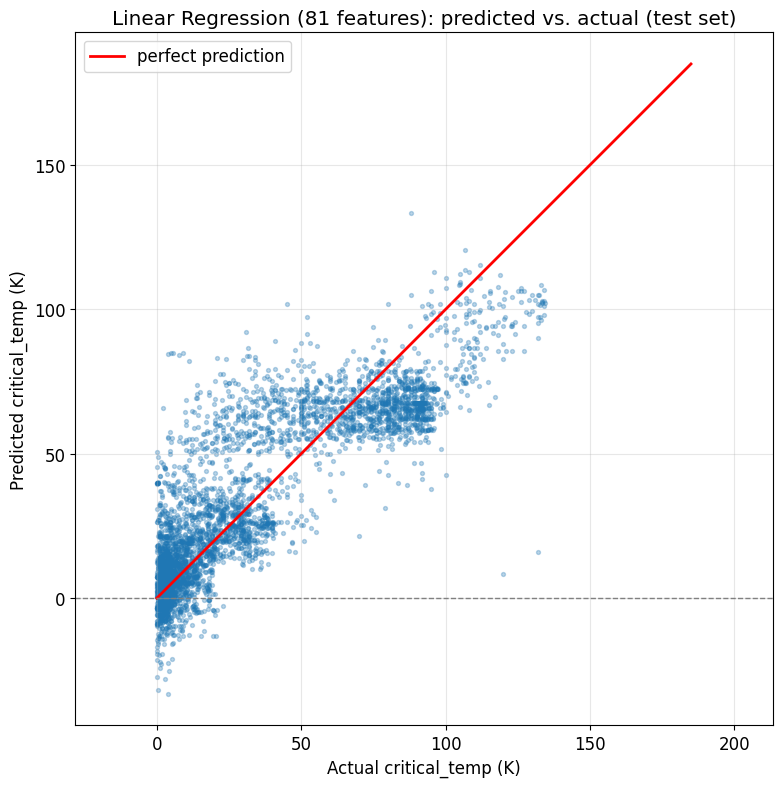

In [144]:
plt.figure(figsize=(9, 9))
plt.scatter(y_test, y_test_pred_all, s=8, alpha=0.3)
plt.plot([0, 185], [0, 185], color='red', linewidth=2, label='perfect prediction')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.xlabel("Actual critical_temp (K)")
plt.ylabel("Predicted critical_temp (K)")
plt.title("Linear Regression (81 features): predicted vs. actual (test set)")
plt.axis('equal')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [145]:
linear_model_all.intercept_

-17.22853060285415

In [146]:
coefficients_all = pd.Series(linear_model_all.coef_, index=X.columns)
coefficients_all.sort_values(key=abs, ascending=False).head(15)

entropy_fie                    -121.350716
entropy_atomic_radius            78.647432
entropy_Valence                  75.791337
wtd_entropy_Valence             -68.300517
wtd_entropy_atomic_radius        43.400594
wtd_entropy_fie                  42.819460
entropy_atomic_mass             -34.107740
wtd_gmean_Valence               -30.210590
wtd_entropy_FusionHeat           26.574923
wtd_mean_Valence                 26.252031
wtd_std_Valence                 -25.217132
wtd_entropy_ElectronAffinity    -21.986501
wtd_entropy_Density             -21.376714
gmean_Valence                    20.307576
entropy_FusionHeat              -19.915193
dtype: float64

In [147]:
coefficients_all[selected_features]

wtd_std_ThermalConductivity    -0.006829
range_atomic_radius             0.207313
wtd_mean_Valence               26.252031
dtype: float64

## 6. Model 2: Polynomial Regression
- Using the same input features from the linear regression model, investigate polynomial regression with degrees **1, 2, 3, 5, and 10**.
- Plot how training and testing R2 change as the polynomial degree increases.
- Can you identify evidence of underfitting or overfitting?

### 6.1 Train models for each degree
For each degree: create the polynomial features, scale them, and fit a linear regression.

**Why scale here?** The raw features go up to ~200, so a degree-10 term can reach ~10²³. With numbers that large, the solver can't fit the model accurately. `StandardScaler` (fit on the training set only) puts every polynomial feature on the same scale.

In [148]:
poly_results = []
degrees = [1, 2, 3, 5, 10]

for degree in degrees:

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train_sel)
    X_test_poly = poly.transform(X_test_sel)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_poly)
    X_test_scaled = scaler.transform(X_test_poly)

    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    poly_results.append({
        'degree': degree,
        'n_features': X_train_poly.shape[1],  
        'train_r2': r2_score(y_train, train_pred),
        'test_r2': r2_score(y_test, test_pred),
        'test_mae': mean_absolute_error(y_test, test_pred),
        'test_mse': mean_squared_error(y_test, test_pred),  
    })

poly_results = pd.DataFrame(poly_results)
poly_results

,degree,n_features,train_r2,test_r2,test_mae,test_mse
0,1,3,0.556640,0.564953,17.560786,512.113625
1,2,9,0.606938,0.619328,15.266248,448.107094
2,3,19,0.612308,0.626688,15.105688,439.442947
3,5,55,0.643609,0.665150,14.232509,394.167854
4,10,285,0.714480,-0.084606,13.383605,1276.739783


### 6.2 Train vs. test R2 plot

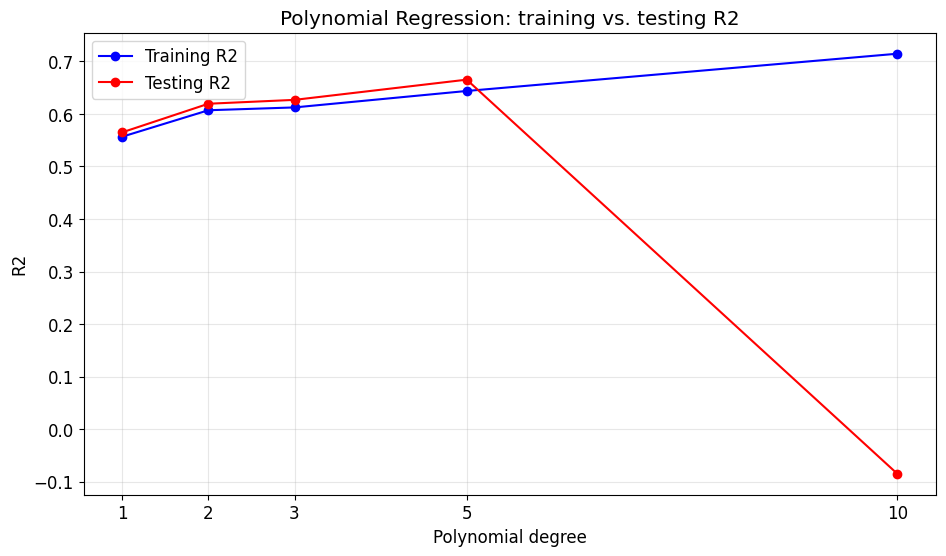

In [149]:
plt.plot(poly_results['degree'], poly_results['train_r2'], color='blue', marker='o', label='Training R2')
plt.plot(poly_results['degree'], poly_results['test_r2'], color='red', marker='o', label='Testing R2')
plt.xticks(degrees)
plt.xlabel("Polynomial degree")
plt.ylabel("R2")
plt.title("Polynomial Regression: training vs. testing R2")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Underfitting (degree 1):** degree 1 is exactly the linear regression from Model 1 (train R2 = 0.557, test R2 = 0.565). The model is too simple to capture the relationship.

**Improving fit (degrees 2 → 5):** both training and testing R2 rise together, up to train = 0.644 and test = 0.665 at degree 5. The curved terms and interactions capture real structure in the data, and the two curves stay close, so there's no overfitting yet.

**Overfitting (degree 10):** training R2 keeps climbing to 0.714, but testing R2 collapses to **−0.085**, which is worse than just predicting the mean critical temperature for every material. This is the classic overfitting signature: the 285-feature model fits the training data better while failing on unseen data.

A detail worth noting at degree 10: the test MAE (13.4 K) is still fine, but the test MSE triples (394 → 1,277). So most predictions are still reasonable, and the damage comes from a small number of wildly wrong ones. A degree-10 polynomial can swing to extreme values for test materials that fall slightly outside the range seen in training, and MSE (and therefore R2) punishes those large errors heavily.

**Best degree: 5** (highest testing R2). Compared to Model 1, polynomial terms on the same 3 features raise the test R2 from 0.565 to 0.665.

## 7. Model 3: Ridge Regression
- Apply Ridge regularization to the polynomial model using an appropriate polynomial degree.
- Try at least three values of alpha (e.g. `0.01, 1, 10`).
- Scale the polynomial features appropriately.

### 7.1 Polynomial features + scaling
**Chosen degree: 10.** Section 6 showed that the degree-10 model overfits badly (train R2 = 0.714, test R2 = −0.085). That makes it the right place to apply regularization: the model has more flexibility than it can handle, and Ridge can rein it in. At degree 5 there's no overfitting to fix, so regularization would have little to do.

The same 3 features and the same degree are used for Polynomial, Ridge and Lasso.

In [150]:
reg_degree = 10

poly = PolynomialFeatures(
    degree=reg_degree,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train_sel)
X_test_poly = poly.transform(X_test_sel)

X_train_poly.shape

(16957, 285)

Ridge and Lasso penalize the size of the coefficients, so every feature must be on the same scale. Otherwise features with large values would be penalized differently from features with small values. The scaler is fit on the training set only.

In [151]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

In [153]:
# Unregularized degree-10 model, for comparison with Ridge and Lasso
poly_model = LinearRegression()
poly_model.fit(X_train_scaled, y_train)

poly_train_pred = poly_model.predict(X_train_scaled)
poly_test_pred = poly_model.predict(X_test_scaled)

print("Train R2:", r2_score(y_train, poly_train_pred))
print("Test R2: ", r2_score(y_test, poly_test_pred))

Train R2: 0.7144804245404236
Test R2:  -0.08460558401751683


### 7.2 Train Ridge for each alpha

In [154]:
alphas = [0.01, 1, 10]

ridge_results = []
ridge_coefs = {}

for alpha in alphas:

    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)

    ridge_train_pred = ridge.predict(X_train_scaled)
    ridge_test_pred = ridge.predict(X_test_scaled)

    ridge_coefs[alpha] = ridge.coef_

    ridge_results.append({
        'alpha': alpha,
        'train_r2': r2_score(y_train, ridge_train_pred),
        'test_r2': r2_score(y_test, ridge_test_pred),
        'test_mae': mean_absolute_error(y_test, ridge_test_pred),
        'test_mse': mean_squared_error(y_test, ridge_test_pred),
    })

ridge_results = pd.DataFrame(ridge_results)
ridge_results

,alpha,train_r2,test_r2,test_mae,test_mse
0,0.01,0.675907,0.676553,13.423167,380.744292
1,1.00,0.657015,0.676150,13.894998,381.218419
2,10.00,0.645430,0.665916,14.176646,393.265455


- **Ridge fixes the overfitting.** Without regularization the degree-10 model scored a test R2 of −0.085. With even the smallest penalty (alpha = 0.01) the test R2 jumps to **0.677**, and training and testing R2 are almost equal (0.676 vs. 0.677).
- **Increasing alpha lowers the training R2** steadily (0.676 → 0.657 → 0.645), because the model is allowed less and less freedom to fit the training data.
- **Testing R2 is almost unchanged from alpha = 0.01 to 1** (0.677 → 0.676) and then starts to drop at alpha = 10 (0.666). A penalty that's too strong pushes the model toward underfitting.
- **Best alpha: 0.01.** This is also slightly better than the best unregularized polynomial model from section 6 (degree 5, test R2 = 0.665), so a regularized degree-10 model makes better use of the 3 features than a plain degree-5 one.

### 7.3 Coefficients

In [155]:
print(ridge_coefs[10][:10])

[ 9.42370852 -6.09370984  1.04663324 -1.65371372  5.05926916  4.7345136
 -5.02033833  2.81035649 -0.75318903 -5.73940583]


In [ ]:
ridge_coef_summary = pd.DataFrame({
    'model': ['No regularization'] + [f'Ridge alpha={a}' for a in alphas],
    'largest |coef|': [abs(poly_model.coef_).max()] + [abs(ridge_coefs[a]).max() for a in alphas],
    'smallest |coef|': [abs(poly_model.coef_).min()] + [abs(ridge_coefs[a]).min() for a in alphas],
    'mean |coef|': [abs(poly_model.coef_).mean()] + [abs(ridge_coefs[a]).mean() for a in alphas]  ,
})
ridge_coef_summary

,model,largest |coef|,smallest |coef|,mean |coef|
0,No regularization,3.603148e+07,8874.622261,3.445681e+06
1,Ridge alpha=0.01,4.859489e+02,1.102182,1.226202e+02
2,Ridge alpha=1,5.779394e+01,0.097363,1.455308e+01
3,Ridge alpha=10,1.770748e+01,0.011104,4.463815e+00


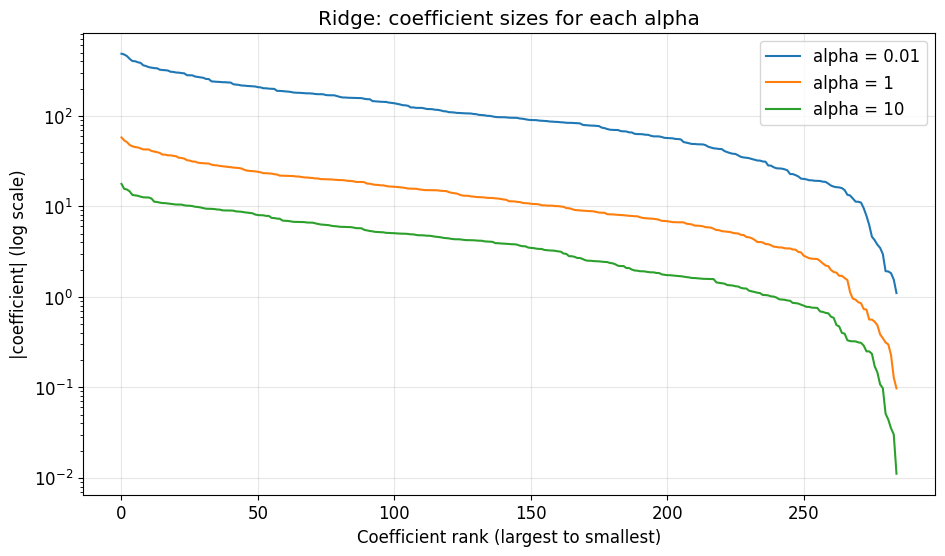

In [ ]:
for alpha in alphas:
    plt.plot(sorted(abs(ridge_coefs[alpha]), reverse=True), label=f'alpha = {alpha}')

plt.yscale('log')
plt.xlabel("Coefficient rank (largest to smallest)")
plt.ylabel("|coefficient| (log scale)")
plt.title("Ridge: coefficient sizes for each alpha")
plt.grid(alpha=0.3)
plt.legend() 
plt.show()

- **Without regularization the coefficients are enormous**: the largest is about 36 million and the average size is about 3.4 million. The model is balancing huge positive and negative terms against each other, which is why a small change in the input produces wild predictions on the test set.
- **Ridge shrinks them.** The largest coefficient is 486 at alpha = 0.01, 58 at alpha = 1 and 18 at alpha = 10. In the plot, each increase in alpha shifts the whole curve down.
- **No coefficient becomes exactly zero.** Ridge makes coefficients small but keeps all 285 polynomial features in the model.

## 8. Model 4: Lasso Regression
- Repeat the previous experiment with Lasso, using the same polynomial features and alpha values as Ridge.
- Investigate how changing alpha affects the coefficients and prediction performance.
- Do any coefficients become exactly zero? Compare with Ridge.

### 8.1 Train Lasso for each alpha
Same scaled degree-10 polynomial features and same alpha values as Ridge.

`max_iter` is raised because Lasso needs many iterations to converge when the features are this strongly correlated. `precompute=True` only speeds up the calculation (it doesn't change the result).

In [ ]:
lasso_results = []
lasso_coefs = {}

for alpha in alphas:

    lasso = Lasso(alpha=alpha, max_iter=1000000, precompute=True)
    lasso.fit(X_train_scaled, y_train)

    lasso_train_pred = lasso.predict(X_train_scaled)
    lasso_test_pred = lasso.predict(X_test_scaled)

    lasso_coefs[alpha] = lasso.coef_

    lasso_results.append({
        'alpha': alpha,
        'train_r2': r2_score(y_train, lasso_train_pred),
        'test_r2': r2_score(y_test, lasso_test_pred),
        'test_mae': mean_absolute_error(y_test, lasso_test_pred),
        'test_mse': mean_squared_error(y_test, lasso_test_pred),
    })

lasso_results = pd.DataFrame(lasso_results)
lasso_results

,alpha,train_r2,test_r2,test_mae,test_mse
0,0.01,0.640708,0.660779,14.318609,399.312951
1,1.00,0.604538,0.617626,15.393352,450.110440
2,10.00,0.516707,0.529173,18.906084,554.232515


- **Lasso also fixes the overfitting**: at alpha = 0.01 the test R2 is 0.661 (vs. −0.085 without regularization), with training and testing scores close together.
- **Performance drops faster as alpha increases** than it did with Ridge: test R2 goes 0.661 → 0.618 → 0.529. At alpha = 10 the model is clearly **underfitting**, scoring worse than the plain 3-feature model of degree 1 (0.565).
- The same alpha value isn't the same strength of penalty in the two models. scikit-learn's Lasso divides the error term by the number of samples and Ridge doesn't, so a given alpha acts much more strongly in Lasso.
- **Best alpha: 0.01**, slightly below the best Ridge model (0.677).

### 8.2 Coefficients and zero count

In [ ]:
print(lasso_coefs[10][:10])

[ 0.          0.         -0.          0.          0.87850819  0.
  0.          0.         -0.          0.        ]


In [ ]:
coef_comparison = pd.DataFrame({
    'alpha': alphas,
    'Ridge: coefs exactly 0': [(ridge_coefs[a] == 0).sum() for a in alphas],
    'Lasso: coefs exactly 0': [(lasso_coefs[a] == 0).sum() for a in alphas],
    'Lasso: features kept': [(lasso_coefs[a] != 0).sum() for a in alphas],
    'Ridge: largest |coef|': [abs(ridge_coefs[a]).max() for a in alphas],
    'Lasso: largest |coef|': [abs(lasso_coefs[a]).max() for a in alphas],
})
coef_comparison

,alpha,Ridge: coefs exactly 0,Lasso: coefs exactly 0,Lasso: features kept,Ridge: largest |coef|,Lasso: largest |coef|
0,0.01,0,244,41,485.948949,74.648596
1,1.00,0,279,6,57.793944,18.745789
2,10.00,0,283,2,17.707479,15.710173


Which polynomial features does Lasso keep?

In [ ]:
feature_names = poly.get_feature_names_out(selected_features)

for alpha in [1, 10]:
    kept = pd.Series(lasso_coefs[alpha], index=feature_names)
    kept = kept[kept != 0]
    print(f"alpha = {alpha}: {len(kept)} features kept")
    print(kept.sort_values(key=abs, ascending=False))
    print()

alpha = 1: 6 features kept
wtd_std_ThermalConductivity range_atomic_radius^2                     18.745789
wtd_std_ThermalConductivity^2 range_atomic_radius                      2.755294
wtd_std_ThermalConductivity range_atomic_radius                        2.300714
wtd_mean_Valence                                                      -2.086747
wtd_std_ThermalConductivity range_atomic_radius wtd_mean_Valence^4    -0.304679
range_atomic_radius^2                                                  0.231912
dtype: float64

alpha = 10: 2 features kept
wtd_std_ThermalConductivity range_atomic_radius^2    15.710173
wtd_std_ThermalConductivity range_atomic_radius       0.878508
dtype: float64



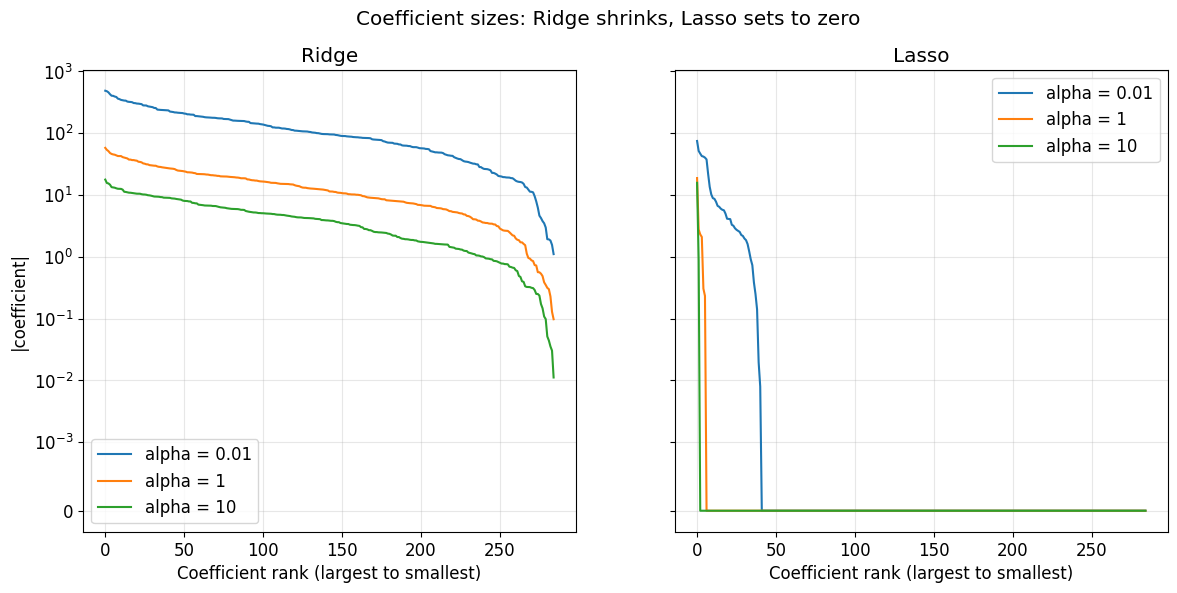

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for alpha in alphas:
    axes[0].plot(sorted(abs(ridge_coefs[alpha]), reverse=True), label=f'alpha = {alpha}')
    axes[1].plot(sorted(abs(lasso_coefs[alpha]), reverse=True), label=f'alpha = {alpha}')

axes[0].set_title("Ridge")
axes[1].set_title("Lasso")
axes[0].set_ylabel("|coefficient|")

for ax in axes:
    ax.set_yscale('symlog', linthresh=1e-3)
    ax.set_xlabel("Coefficient rank (largest to smallest)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Coefficient sizes: Ridge shrinks, Lasso sets to zero")
plt.show()

**Do any coefficients become exactly zero?** Yes, most of them:

| alpha | Lasso: coefficients at zero | Lasso: features kept | Ridge: coefficients at zero |
|---|---|---|---|
| 0.01 | 244 of 285 | 41 | 0 |
| 1 | 279 of 285 | 6 | 0 |
| 10 | 283 of 285 | 2 | 0 |

**Lasso vs. Ridge:**
- **Ridge shrinks, Lasso selects.** Ridge keeps all 285 features with small coefficients. Lasso sets most coefficients to exactly zero, which removes those features from the model. The plot shows this clearly: the Ridge curves slide down as alpha grows, while the Lasso curves drop straight to zero.
- **Lasso gives a much simpler model.** At alpha = 0.01 it reaches a test R2 of 0.661 using only 41 features, close to Ridge's 0.677 with all 285.
- **Which features survive:** at alpha = 1, only 6 terms remain, and most are low-degree interactions between thermal conductivity and atomic radius. At alpha = 10, only 2 remain, both thermal conductivity × atomic radius terms. This says that most of the 285 polynomial terms, especially the high-degree ones, aren't needed. The useful signal is mainly in how these two properties combine.
- **Prediction accuracy:** Ridge is slightly better at every alpha here. Lasso trades a little accuracy for a model that's far easier to interpret.

## 9. Model Comparison
Prepare a table reporting the performance of all models.

Polynomial, Ridge and Lasso use the same 3 input features and the same polynomial degree (10), for a fair comparison. Linear regression is shown twice: with the same 3 features, and with all 81.

In [ ]:
poly_row = poly_results[poly_results['degree'] == reg_degree].iloc[0]
poly5_row = poly_results[poly_results['degree'] == 5].iloc[0]

rows = [
    ['Linear Regression', '3', 1, '-',
     lr_train_r2, lr_test_r2, lr_mae, lr_mse],
    ['Linear Regression', '81 (all)', 1, '-',
     lr_all_train_r2, lr_all_test_r2, lr_all_mae, lr_all_mse],
    ['Polynomial Regression', '3', reg_degree, '-',
     poly_row['train_r2'], poly_row['test_r2'], poly_row['test_mae'], poly_row['test_mse']],
]

for _, r in ridge_results.iterrows():
    rows.append(['Ridge Regression', '3', reg_degree, r['alpha'],
                 r['train_r2'], r['test_r2'], r['test_mae'], r['test_mse']])

for _, r in lasso_results.iterrows():
    rows.append(['Lasso Regression', '3', reg_degree, r['alpha'],
                 r['train_r2'], r['test_r2'], r['test_mae'], r['test_mse']])

rows.append(['Polynomial Regression (reference)', '3', 5, '-',
             poly5_row['train_r2'], poly5_row['test_r2'], poly5_row['test_mae'], poly5_row['test_mse']])

comparison = pd.DataFrame(
    rows,
    columns=['Model', 'Features', 'Degree', 'Alpha', 'Train R2', 'Test R2', 'Test MAE', 'Test MSE']
)
comparison.round(3)

,Model,Features,Degree,Alpha,Train R2,Test R2,Test MAE,Test MSE
0,Linear Regression,3,1,-,0.557,0.565,17.561,512.114
1,Linear Regression,81 (all),1,-,0.737,0.735,13.270,311.520
2,Polynomial Regression,3,10,-,0.714,-0.085,13.384,1276.740
3,Ridge Regression,3,10,0.01,0.676,0.677,13.423,380.744
4,Ridge Regression,3,10,1.0,0.657,0.676,13.895,381.218
5,Ridge Regression,3,10,10.0,0.645,0.666,14.177,393.265
6,Lasso Regression,3,10,0.01,0.641,0.661,14.319,399.313
7,Lasso Regression,3,10,1.0,0.605,0.618,15.393,450.110
8,Lasso Regression,3,10,10.0,0.517,0.529,18.906,554.233
9,Polynomial Regression (reference),3,5,-,0.644,0.665,14.233,394.168


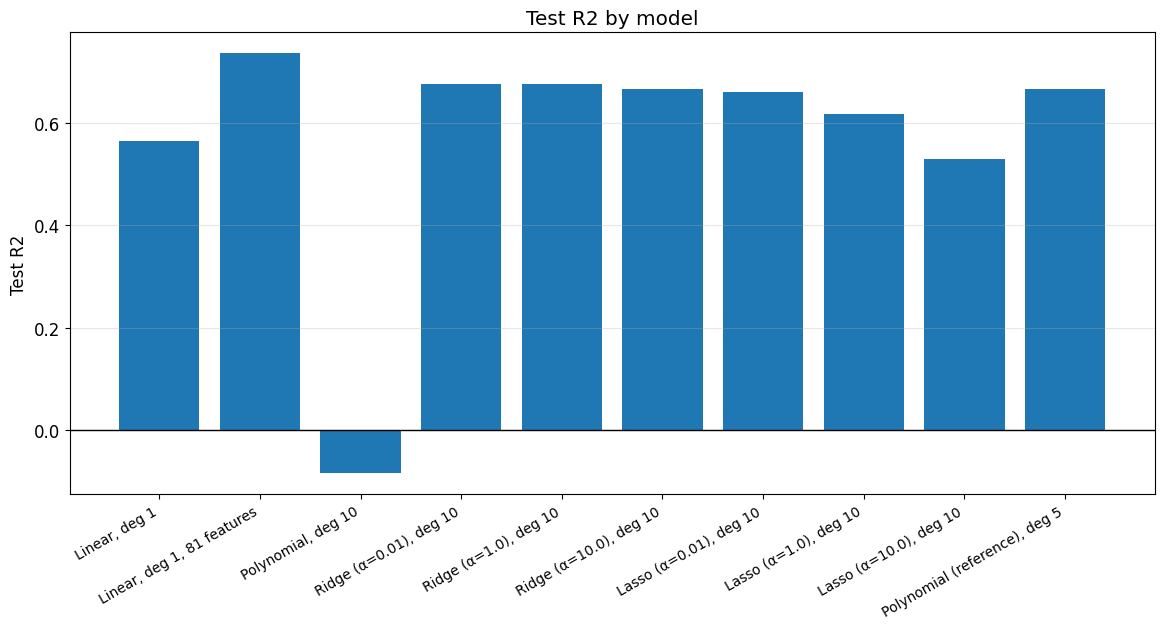

In [ ]:
labels = comparison['Model'].str.replace(' Regression', '') + comparison['Alpha'].apply(
    lambda a: '' if a == '-' else f' (α={a})'
) + comparison['Degree'].apply(lambda d: f', deg {d}') + comparison['Features'].apply(
    lambda f: ', 81 features' if f == '81 (all)' else ''
)

plt.figure(figsize=(14, 6))
plt.bar(labels, comparison['Test R2'])
plt.axhline(0, color='black', linewidth=1)
plt.ylabel("Test R2")
plt.title("Test R2 by model")
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.grid(axis='y', alpha=0.3)
plt.show()

- **Linear Regression with all 81 features has the best test performance**: the highest test R2 (0.735) and the lowest MAE (13.3 K) and MSE (312).
- **Among the models that use the same 3 features:**
  - **Linear Regression** underfits: train and test R2 are both low (0.557 and 0.565).
  - **Polynomial Regression (degree 10)** overfits: the highest training R2 of the group (0.714) but a negative test R2.
  - **Ridge** (alpha = 0.01) is the best of the group, with a test R2 of 0.677.
  - **Lasso** (alpha = 0.01) is close behind at 0.661, using only 41 of the 285 polynomial features. At alpha = 10 it's penalized so strongly that it falls below the 3-feature linear model (0.529).
- **MAE and MSE tell different stories for the overfit polynomial model.** Its MAE (13.4 K) is as good as Ridge's, but its MSE is more than three times higher (1,277 vs. 381). Most of its predictions are fine. A few are extremely wrong, and MSE and R2 penalize those heavily.
- The degree-5 polynomial row is included only as a reference: it was the best unregularized degree in section 6.

## 10. Conclusion
**Which model makes the most accurate predictions on unseen data?**

**Multiple Linear Regression using all 81 features**: test R2 = 0.735, MAE = 13.3 K, MSE = 312. For this dataset, having more information (81 features) mattered more than having a more flexible model (polynomial terms on 3 features).

Among the models built on the same 3 features, **Ridge Regression (degree 10, alpha = 0.01)** is the most accurate, with a test R2 of 0.677.

**What each model showed:**
- **Linear Regression, 3 features (test R2 = 0.565):** a simple baseline with coefficients that are easy to read, but it underfits. It can't predict above ~70 K.
- **Linear Regression, 81 features (test R2 = 0.735):** the most accurate model, with no overfitting, but its coefficients can't be interpreted because the features are strongly correlated with each other.
- **Polynomial Regression:** adding polynomial terms helps up to degree 5 (test R2 0.565 → 0.665). At degree 10 the model overfits and fails on unseen data (test R2 = −0.085).
- **Ridge Regression (test R2 = 0.677):** shrinking the coefficients fixes the overfitting completely and turns the worst model into the best 3-feature model.
- **Lasso Regression (test R2 = 0.661):** fixes the overfitting too, and also removes most features by setting their coefficients to exactly zero. It's slightly less accurate than Ridge but much simpler.

The pattern among the 3-feature models: a model that's too simple underfits, a model that's too flexible overfits, and a flexible model with regularization does best.

**Back to the original question:** can the chemical properties of a material predict the temperature at which it becomes superconductive? Partly. The best model explains about 74% of the variation in critical temperature, with an average error of about 13 K. That's useful for a rough estimate, but not precise, given that half of the materials have a critical temperature below 20 K.

**Limitations:**
- The polynomial, Ridge and Lasso models use only 3 of the 81 features, to keep them computable. A regularized polynomial model on more features might beat the 81-feature linear model, but that wasn't tested.
- The best alpha was picked by looking at test scores for only three values. Cross-validation over more values would be a more reliable way to choose it.
- Some materials appear more than once in the dataset with different measured temperatures, so the same material can be in both the training and test sets. Test scores may be somewhat optimistic for truly new materials.